In [1]:
%pip install -q scikit-learn==1.9.1

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    ConfusionMatrixDisplay
)
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

#2. Load the original Wisconsin Breast Cancer dataset

In [3]:

url = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "breast-cancer-wisconsin/breast-cancer-wisconsin.data"
)

columns = [
    "Sample ID", "Clump thickness", "Cell size uniformity",
    "Cell shape uniformity", "Marginal adhesion", "Epithelial cell size",
    "Bare nuclei", "Bland chromatin", "Normal nucleoli", "Mitoses", "Class"
]

df = pd.read_csv(url, header=None, names=columns, na_values="?")


In [4]:
# Use sample IDs to keep repeated IDs together during cross-validation.
groups = df["Sample ID"]
X = df.drop(columns=["Sample ID", "Class"])

# Map the original labels to 0 = benign and 1 = malignant.
y = df["Class"].map({2: 0, 4: 1})

#3. Explore the data and check missing values

,Sample ID,Clump thickness,Cell size uniformity,Cell shape uniformity,Marginal adhesion,Epithelial cell size,Bare nuclei,Bland chromatin,Normal nucleoli,Mitoses,Class
0,1000025,5,1,1,1,2,1.0,3,1,1,2
1,1002945,5,4,4,5,7,10.0,3,2,1,2
2,1015425,3,1,1,1,2,2.0,3,1,1,2
3,1016277,6,8,8,1,3,4.0,3,7,1,2
4,1017023,4,1,1,3,2,1.0,3,1,1,2


,Clump thickness,Cell size uniformity,Cell shape uniformity,Marginal adhesion,Epithelial cell size,Bare nuclei,Bland chromatin,Normal nucleoli,Mitoses
count,699.00,699.00,699.00,699.00,699.00,683.00,699.00,699.00,699.00
mean,4.42,3.13,3.21,2.81,3.22,3.54,3.44,2.87,1.59
std,2.82,3.05,2.97,2.86,2.21,3.64,2.44,3.05,1.72
min,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
25%,2.00,1.00,1.00,1.00,2.00,1.00,2.00,1.00,1.00
50%,4.00,1.00,1.00,1.00,2.00,1.00,3.00,1.00,1.00
75%,6.00,5.00,5.00,4.00,4.00,6.00,5.00,4.00,1.00
max,10.00,10.00,10.00,10.00,10.00,10.00,10.00,10.00,10.00


,Missing values
Clump thickness,0
Cell size uniformity,0
Cell shape uniformity,0
Marginal adhesion,0
Epithelial cell size,0
Bare nuclei,16
Bland chromatin,0
Normal nucleoli,0
Mitoses,0


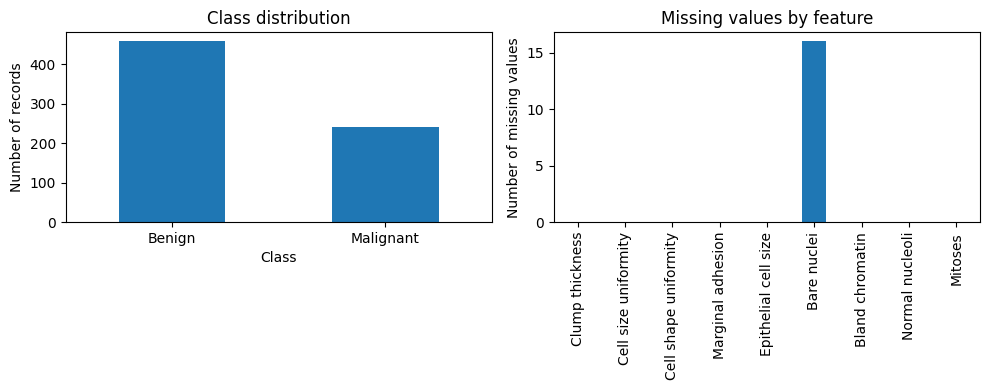

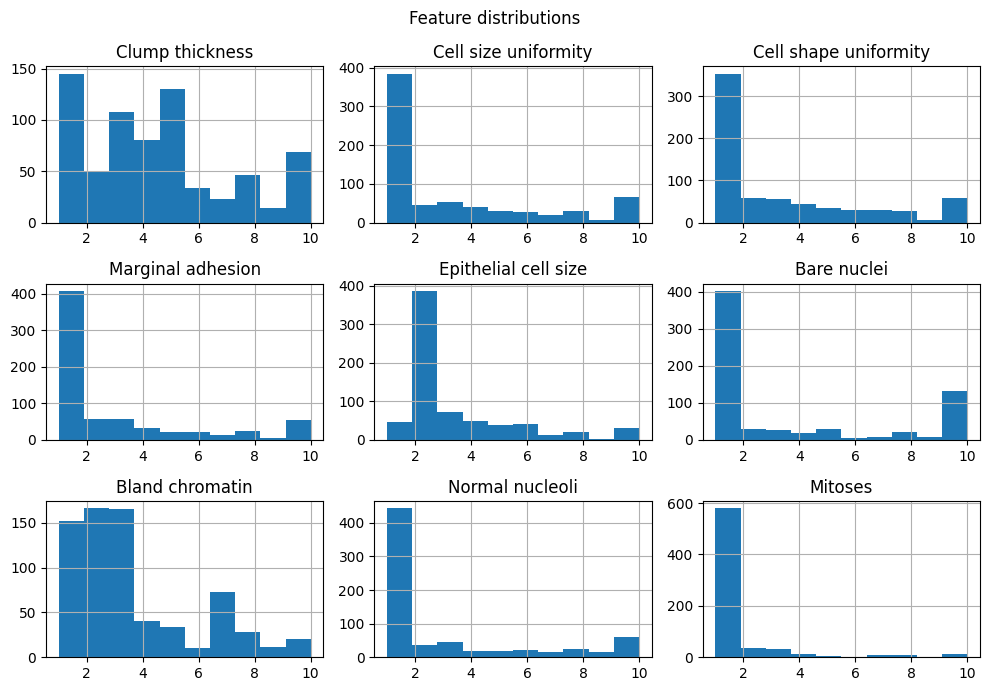

In [5]:
display(df.head())
display(X.describe().round(2))
display(X.isna().sum().rename("Missing values").to_frame())

class_counts = y.map({0: "Benign", 1: "Malignant"}).value_counts()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
class_counts.plot.bar(ax=axes[0], rot=0, title="Class distribution")
axes[0].set_ylabel("Number of records")

X.isna().sum().plot.bar(ax=axes[1], title="Missing values by feature")
axes[1].set_ylabel("Number of missing values")

plt.tight_layout()
plt.show()

X.hist(figsize=(10, 7), bins=10)
plt.suptitle("Feature distributions")
plt.tight_layout()
plt.show()

#4. Set up KNN with an adjustable cutoff for the malignant class


In [6]:
class RecallKNN(KNeighborsClassifier):
    def __init__(self, n_neighbors=5, weights="uniform", p=2, threshold=0.5):
        super().__init__(n_neighbors=n_neighbors, weights=weights, p=p)
        self.threshold = threshold

    def predict(self, X):
        malignant_probability = self.predict_proba(X)[:, 1]
        return (malignant_probability >= self.threshold).astype(int)


# The pipeline learns medians and scaling values inside each training fold.
model = Pipeline([
    ("fill", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("knn", RecallKNN())
])

parameters = {
    "knn__n_neighbors": [5, 9, 15],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],  # 1 = Manhattan, 2 = Euclidean
    "knn__threshold": [0.25, 0.35, 0.45, 0.50]
}


# 5. Prioritize malignant recall during tuning

In [7]:
def choose_model(results):
    precision = results["mean_test_precision"]
    recall = results["mean_test_recall"]

    eligible = [i for i, score in enumerate(precision) if score >= 0.95]

    # If no setting reaches 95% validation precision, select by recall.
    candidates = eligible or range(len(precision))
    return max(candidates, key=lambda i: (recall[i], precision[i]))


# Inner folds select the settings. Outer folds evaluate those settings.
inner_cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=42)
outer_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)

search = GridSearchCV(
    estimator=model,
    param_grid=parameters,
    cv=inner_cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall"
    },
    refit=choose_model,
    n_jobs=1
)



# 6. Evaluate each held-out fold and calculate log loss

In [8]:
predictions = pd.Series(index=y.index, dtype="float64")
malignant_probabilities = pd.Series(index=y.index, dtype="float64")
fold_scores = []

for fold, (train, test) in enumerate(outer_cv.split(X, y, groups), start=1):
    X_train, X_test = X.iloc[train], X.iloc[test]
    y_train, y_test = y.iloc[train], y.iloc[test]

    search.fit(X_train, y_train, groups=groups.iloc[train])

    predicted = search.predict(X_test)
    probabilities = search.predict_proba(X_test)

    predictions.iloc[test] = predicted
    malignant_probabilities.iloc[test] = probabilities[:, 1]

    fold_scores.append({
        "Fold": fold,
        "Accuracy (%)": accuracy_score(y_test, predicted) * 100,
        "Malignant precision (%)": precision_score(
            y_test, predicted, zero_division=0
        ) * 100,
        "Malignant recall (%)": recall_score(
            y_test, predicted, zero_division=0
        ) * 100,
        "Malignant F1 (%)": f1_score(
            y_test, predicted, zero_division=0
        ) * 100,
        "Log loss": log_loss(y_test, probabilities, labels=[0, 1])
    })

fold_table = pd.DataFrame(fold_scores).set_index("Fold")
display(fold_table.round(4))


,Accuracy (%),Malignant precision (%),Malignant recall (%),Malignant F1 (%),Log loss
Fold,,,,,
1,95.6835,92.0000,95.8333,93.8776,0.5977
2,97.1223,95.8333,95.8333,95.8333,0.5647
3,97.8723,96.0000,97.9592,96.9697,0.0728
4,97.1429,95.8333,95.8333,95.8333,0.3102
5,96.4286,90.5660,100.0000,95.0495,0.0734


# 7. Report results across all held-out predictions

,Overall held-out results
Accuracy (%),96.8526
Malignant precision (%),93.9759
Malignant recall (%),97.0954
Malignant F1 (%),95.5102
Log loss,0.3227


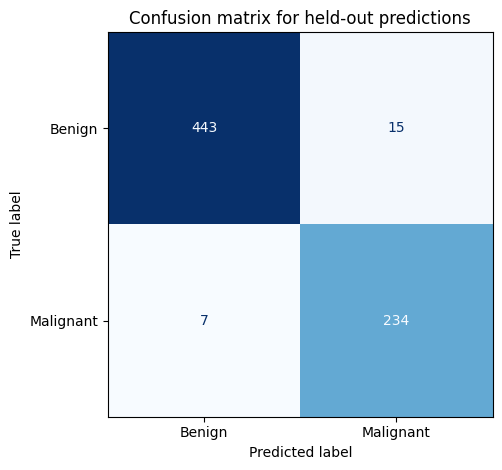

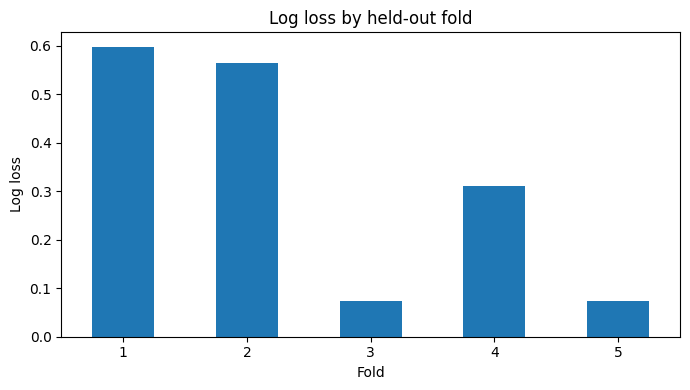

In [9]:
predictions = predictions.astype(int)

# Put the probability columns in the same order as labels [0, 1].
all_probabilities = pd.DataFrame({
    0: 1 - malignant_probabilities,
    1: malignant_probabilities
})

scores = pd.Series({
    "Accuracy (%)": accuracy_score(y, predictions) * 100,
    "Malignant precision (%)": precision_score(
        y, predictions, zero_division=0
    ) * 100,
    "Malignant recall (%)": recall_score(
        y, predictions, zero_division=0
    ) * 100,
    "Malignant F1 (%)": f1_score(
        y, predictions, zero_division=0
    ) * 100,
    "Log loss": log_loss(y, all_probabilities, labels=[0, 1])
})

display(scores.round(4).to_frame("Overall held-out results"))

ConfusionMatrixDisplay.from_predictions(
    y,
    predictions,
    labels=[0, 1],
    display_labels=["Benign", "Malignant"],
    cmap="Blues",
    colorbar=False
)
plt.title("Confusion matrix for held-out predictions")
plt.tight_layout()
plt.show()

fold_table["Log loss"].plot.bar(figsize=(7, 4), rot=0)
plt.title("Log loss by held-out fold")
plt.ylabel("Log loss")
plt.tight_layout()
plt.show()

# 8. Fit the final model and check missing values after imputation


In [10]:
search.set_params(return_train_score=True)
search.fit(X, y, groups=groups)

final_model = search.best_estimator_
display(pd.Series(search.best_params_).to_frame("Selected setting"))

filled_X = pd.DataFrame(
    final_model.named_steps["fill"].transform(X),
    columns=X.columns
)

display(pd.DataFrame({
    "Missing before": X.isna().sum(),
    "Missing after": filled_X.isna().sum()
}))

,Selected setting
knn__n_neighbors,15
knn__p,1
knn__threshold,0.25
knn__weights,uniform


,Missing before,Missing after
Clump thickness,0,0
Cell size uniformity,0,0
Cell shape uniformity,0,0
Marginal adhesion,0,0
Epithelial cell size,0,0
Bare nuclei,16,0
Bland chromatin,0,0
Normal nucleoli,0,0
Mitoses,0,0


# 9. Plot training and validation accuracy as K changes


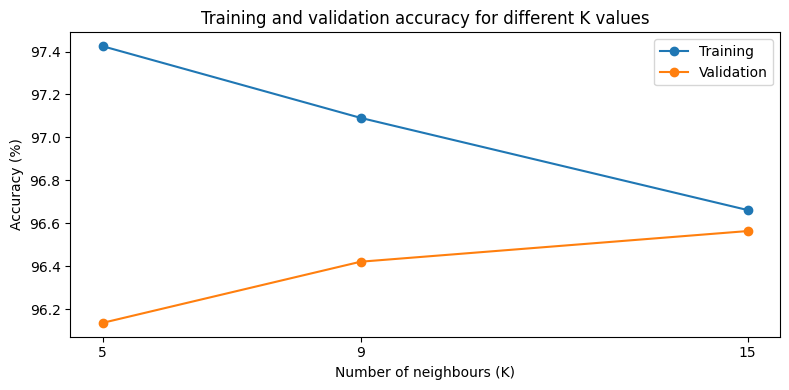

In [11]:
results = pd.DataFrame(search.cv_results_)

# Fix the other settings so the graph shows the effect of changing K.
curve = results.loc[
    (results["param_knn__weights"] == "uniform") &
    (results["param_knn__p"] == 2) &
    (results["param_knn__threshold"] == 0.50)
].sort_values("param_knn__n_neighbors")

k_values = curve["param_knn__n_neighbors"].astype(int)

plt.figure(figsize=(8, 4))
plt.plot(k_values, curve["mean_train_accuracy"] * 100,
         marker="o", label="Training")
plt.plot(k_values, curve["mean_test_accuracy"] * 100,
         marker="o", label="Validation")
plt.xticks(k_values)
plt.xlabel("Number of neighbours (K)")
plt.ylabel("Accuracy (%)")
plt.title("Training and validation accuracy for different K values")
plt.legend()
plt.tight_layout()
plt.show()